ECE 3715 Mini Project 1

Team Members: Jovanni Munoz, Ryan Mascola, Andy Nguyen, Miguel Guardado

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import binom, poisson, geom
from scipy.stats import norm

from mp1lib import (
    bsc,
    packet_errors,
    attempts_until_clean,
    tv_distance
)

print("Setup complete.")

Setup complete.


In [10]:
# Main random number generator (Team number=5)
SEED = 5
rng = np.random.default_rng(SEED)

# Independent generators with one for each step
rng_step1 = rng.spawn(1)[0]
rng_step2 = rng.spawn(1)[0]
rng_step3 = rng.spawn(1)[0]
rng_step4 = rng.spawn(1)[0]
rng_step5 = rng.spawn(1)[0]
rng_step6 = rng.spawn(1)[0]
rng_step7 = rng.spawn(1)[0]
rng_step8 = rng.spawn(1)[0]

N = 1000000

# Test: BSC and it must return [0, 1, 0, 1] because the p=0
bits = np.array([0, 1, 0, 1])
print(bsc(bits, 0, rng_step1))

# Test: Packet errors
x = packet_errors(10000, 1000, 0, rng_step4)
assert np.all(x == 0)

# Test: Geometric attempts
t = attempts_until_clean(10000, 1, rng_step6)
assert np.all(t == 1)

# Test: Total variation distance
assert tv_distance([0.5, 0.5], [0.5, 0.5]) == 0
assert tv_distance([1, 0], [0, 1]) == 1
print("All function tests passed.")

[0 1 0 1]
All function tests passed.


In [30]:
#Set error probability and create a list
p = 0.1
patterns = []
#Go through all possible bit combinations and change them to binary format
for i in range(16):
    pattern = format(i, "04b")
    patterns.append(pattern)
#Display all bit combinations
print(patterns)
#create a list for the probability of each bit combination
exact_probabilities = []
#Use the formula to calculate probability of each combination
for pattern in patterns:
    k = pattern.count("1")
    probability = (p ** k) * ((1-p) ** (4-k))
    exact_probabilities.append(probability)
#Display the probability of each combination and its sum
print(exact_probabilities)
print("Sum =", sum(exact_probabilities))

['0000', '0001', '0010', '0011', '0100', '0101', '0110', '0111', '1000', '1001', '1010', '1011', '1100', '1101', '1110', '1111']
[0.6561, 0.0729, 0.0729, 0.008100000000000001, 0.0729, 0.008100000000000001, 0.008100000000000001, 0.0009000000000000002, 0.0729, 0.008100000000000001, 0.008100000000000001, 0.0009000000000000002, 0.008100000000000001, 0.0009000000000000002, 0.0009000000000000002, 0.00010000000000000002]
Sum = 1.0


P(A) = 1−(1−p)^2
P(A) = 1-(1-.1)^2
P(A) = 1-.81 = .19

P(A) = .19


P(B) =  \({4 \choose 2}\)*p^2(1-p)^2
P(B) = (6)*.1^2(1-.1)^2
P(B) = (6)*.1^2(.9)^2

P(B) = .0486

P(C) = .1

In [55]:
#Generate 1000000 packets with 4 bits in each one and error probability of .1
N = 1000000
errors = rng_step1.random((N1, 4)) < 0.1
#Check if A, B, and C happen and how many times
A = np.any(errors[:, :2], axis=1)
B = errors.sum(axis=1) == 2
C = errors[:, 3] 
events = [A, B, C]
#Estimate probability that each one happens
for name, event in zip(["A", "B", "C"], events):
    A_estimate = A.mean()
    B_estimate = B.mean()
    C_estimate = C.mean()

print("Estimate A:", A_estimate)
print("Estimate B:", B_estimate)
print("Estimate C:", C_estimate)

Estimate A: 0.190439
Estimate B: 0.048877
Estimate C: 0.100306


In [80]:
#Compute three pairwise intersections and triple intersections empirically
pairs = [
    ("A and B:", A & B),
    ("A and C:", A & C),
    ("B and C:", B & C),
    ("A and B and C:", A & B & C)
]
AB, AC, BC, ABC = [pair[1] for pair in pairs]

AB_estimate = AB.mean()
AC_estimate = AC.mean()
BC_estimate = BC.mean()
ABC_estimate = ABC.mean()

#print probability of each pair
print("Estimate A and B:", AB_estimate)
print("Estimate A and C:", AC_estimate)
print("Estimate B and C:", BC_estimate)
print("Estimate A and B and C:", ABC_estimate)

Estimate A and B: 0.040735
Estimate A and C: 0.018983
Estimate B and C: 0.024265
Estimate A and B and C: 0.016123


In [32]:
#Compute three pairwise intersections and triple intersections exactly using original 16 patterns
patterns = np.array(patterns)
exact_probabilities = np.array(exact_probabilities)
A_exact = np.array([pattern[0] == "1" or pattern[1] == "1" for pattern in patterns])
B_exact = np.array([pattern.count("1") == 2 for pattern in patterns])
C_exact = np.array([pattern[3] == "1" for pattern in patterns])
P_AB = np.sum(exact_probabilities[A_exact & B_exact])
P_AC = np.sum(exact_probabilities[A_exact & C_exact])
P_BC = np.sum(exact_probabilities[B_exact & C_exact])
P_ABC = np.sum(exact_probabilities[A_exact & B_exact & C_exact])

#print probability of each pair exactly
print("Exact P(A and B) =", P_AB)
print("Exact P(A and C) =", P_AC)
print("Exact P(B and C) =", P_BC)
print("Exact P(A and B and C) =", P_ABC)

Exact P(A and B) = 0.04050000000000001
Exact P(A and C) = 0.019000000000000006
Exact P(B and C) = 0.024300000000000002
Exact P(A and B and C) = 0.016200000000000003


Exact P(A∪B∪C)= P(A)+P(B)+P(C)−P(A∩B)−P(A∩C)−P(B∩C)+P(A∩B∩C)

Exact P(A∪B∪C)= .19+.0486+.1-0.04050000000000001-0.04050000000000001-0.024300000000000002+0.016200000000000003

Exact P(A∪B∪C)= .271

In [37]:
#exact probability of A, B, and C
P_A = np.sum(exact_probabilities[A_exact])
P_B = np.sum(exact_probabilities[B_exact])
P_C = np.sum(exact_probabilities[C_exact])

#use exact probability to calculate exact probability of the inclusion-exclusion formula
P_union = P_A + P_B + P_C - P_AB - P_AC - P_BC + P_ABC
print("Exact P(A or B or C) =", P_union)

Exact P(A or B or C) = 0.271


In [54]:
#use empirical probability to calculate empirical probability of the inclusion-exclusion formula
P_estimate = A_estimate + B_estimate + C_estimate - AB_estimate - AC_estimate - BC_estimate + ABC_estimate
print("Empirical P(A or B or C) =", P_estimate)

Empirical P(A or B or C) = 0.27134600000000003


In [78]:
#standard error of probability estimate at N=10^6
N = 10**6
#standard error formula
def standard_error(phat, N):
    return np.sqrt(phat * (1 - phat) / N)
#standard error of probability A estimate
stde_A = standard_error(A_estimate, N)
#display standard error
print("Standard Error:", stde_A)

Standard Error: 0.0003926474083436691


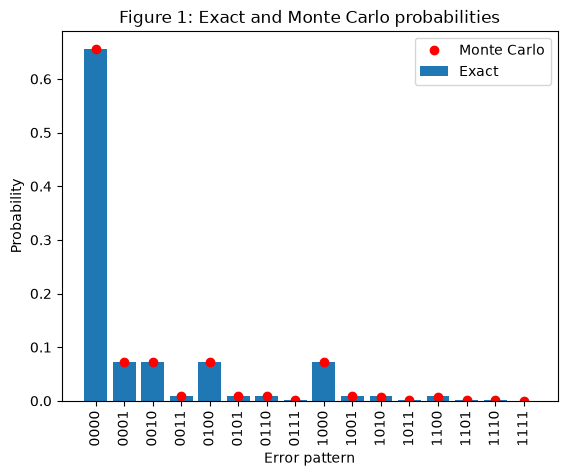

In [81]:
#plot the figure bar chart with x values and label the bar chart Exact
plt.figure()
x = np.arange(16)
plt.bar(x, exact_probabilities, label="Exact")

#Monte Carlo estimates with different patterns and their values 
mc_probability_pattern = np.zeros(16)
"""determines which of the 1 million packets have an exact pattern so that it can use it as an 
estimate for that pattern"""
for i, pattern in enumerate(patterns):
    mc_probability_pattern[i] = np.mean(np.all(errors == np.array([c == "1" for c in pattern]), axis=1))

#plot Monte Carlo estimates
plt.plot(x, mc_probability_pattern, "o", label="Monte Carlo", color="red")

#label the axis and chart
plt.xlabel("Error pattern")
plt.ylabel("Probability")
plt.title("Figure 1: Exact and Monte Carlo probabilities")
plt.xticks(x, patterns, rotation=90)
plt.legend()
plt.show()

The figure 1 is comparison between exact and Monte Carlo Probabilities to show how different the value is when numerous trials are taken. Thus, it shows the exact probability of getting each case with different number of errors and the probability of getting each case when 1000 trials are conducted with Monte Carlo estimate.

In [82]:
import pandas as pd

#Seven exact probabilities
exact = np.array([P_A, P_B, P_C, P_AB, P_AC, P_BC, P_ABC])

#Seven empirical probabilities from Monte Carlo
empirical = np.array([A_estimate, B_estimate, C_estimate, AB_estimate, AC_estimate, BC_estimate, ABC_estimate])

#Difference between empirical and exact
difference = empirical - exact

#Label the values on table
table = pd.DataFrame({"Probability": ["P(A)", "P(B)", "P(C)", "P(A ∩ B)", "P(A ∩ C)", "P(B ∩ C)", "P(A ∩ B ∩ C)"],
                      "Exact": exact,
                      "Empirical": empirical,
                      "Difference": difference})

#Display the table
print(table.to_string(index=False))

 Probability  Exact  Empirical  Difference
        P(A) 0.1900   0.190439    0.000439
        P(B) 0.0486   0.048877    0.000277
        P(C) 0.1000   0.100306    0.000306
    P(A ∩ B) 0.0405   0.040735    0.000235
    P(A ∩ C) 0.0190   0.018983   -0.000017
    P(B ∩ C) 0.0243   0.024265   -0.000035
P(A ∩ B ∩ C) 0.0162   0.016123   -0.000077


STEP 2

In [105]:
# Step 1: Write down the two conditional probabilities and the prior.  Derive posterior probability (Bayes) truely in error as function of P.
# Events:
#Event 

Events

Event A: Bit is in error Event B: Bit is flagged for being in error

Conditionl Probabilities: P(B|A) = 0.95 P(B'|A') = 0.98

Finding P(A|B) using Baye's Rule:

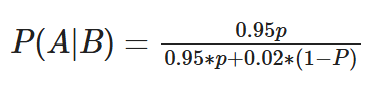


In [106]:
#Evaulate the posterior at:
#
#a) p = 0.1

def agivenb(p):
    result = (0.95*p)/(0.95*p+0.02*(1-p))
    return result

    
print("Solution at p = 0.1:", round(agivenb(0.1),3))
print("Solution at p = 0.01:", round(agivenb(0.01),3))
print("Solution at p = 0.001:", round(agivenb(0.001),3))

Solution at p = 0.1: 0.841
Solution at p = 0.01: 0.324
Solution at p = 0.001: 0.045


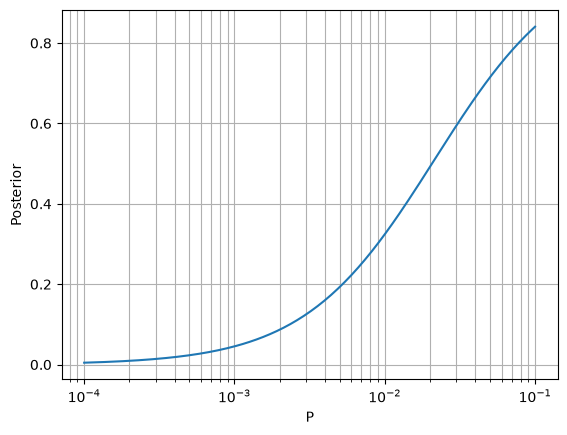

In [107]:
import numpy as np
import matplotlib.pyplot as plt

p = np.logspace(-4, -1, 200)
result = (0.95*p)/(0.95*p+0.02*(1-p))

plt.semilogx(p,result)

plt.xlabel("P")
plt.ylabel("Posterior")
plt.grid(True, which = "both")
plt.show()

Solution:  0.0206


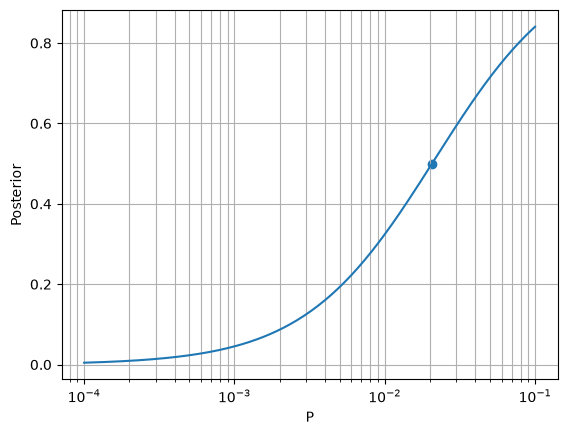

In [108]:
import sympy as sp


p = sp.symbols('p')
result = sp.Eq(0.5,(0.95*p)/(0.95*p+0.02*(1-p)))
x = sp.solve(result, p)



x_point = float(x[0])
y_point = 0.5
print("Solution: ", round(x_point, 4))
p = np.logspace(-4, -1, 200)
result = (0.95*p)/(0.95*p+0.02*(1-p))

plt.semilogx(p,result)
plt.scatter(x_point, y_point)

plt.xlabel("P")
plt.ylabel("Posterior")
plt.grid(True, which = "both")
plt.show()

Using Monte Carlo Simulating sending a bunch of bits to see what happens

In [110]:
rng = np.random.default_rng(5)

def bsc(bits, p, rng):
    #my idea: randomly generate which positions are flipped.  Array of normal bits and rern array

    flippedBitsNum = int(round(len(bits)*p,1))

    for i in range(flippedBitsNum):
        #generate random number
        flipBit = rng.integers(0, len(bits) + 1)
        #flip bit in array
        bits[flipBit] ^= 1  #using XOR to flip it!

    return bits

# this function above will be called from seperate doc.  Let's pass in array of just ones

# the function below will act like our circuit.  For this example. I'll consider 0s as errors


def error_circuit(bits):
    flag = 0
    flagInError = 0
    for i in range(len(bits)):
        if bits[i] == 0:
            if rng.random() < 0.95:
                flag += 1
                flagInError += 1  #actually in error
        else:
           if rng.random() < 0.02:
                flag += 1
    #return ratio of flagged & in error to just flagged 
    ratio = flagInError/flag
    return ratio

array = np.ones(10**7, dtype=int)
ratio = error_circuit(bsc(array, 0.0206, rng))

            
print("The ratio of flagged bits in error to flagged bits is", round(ratio, 4)) 

The ratio of flagged bits in error to flagged bits is 0.4943


If there is a good link and the number of bits in error is very low, the odds of the flag actually signifying an error is also very low. For example, if p = 0.01, the flag will only be right 32.5% of the time. Even though the circuit is 95% accurate, in reality, the when accounting for conditional probability, that number is much smaller than one would intuitively assume.

STEP 3

## Step 3 - Independence
For two fair coin flips, the sample space is

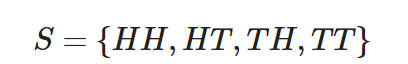
Each outcome has probability

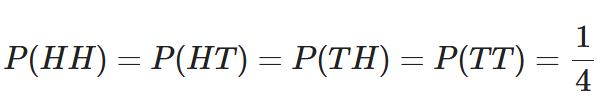


## Define the three events.

E1 is the event that the first coin is Heads.

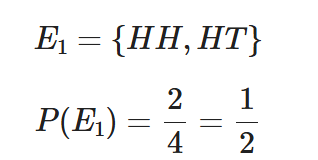

E2 is the event that the second coin is Heads.

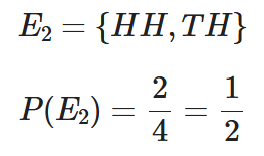

E3 is the event that the two coins match.

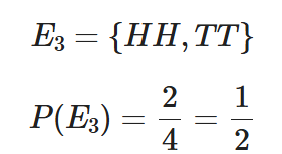

## Check independence of E1 and E2
The intersection is

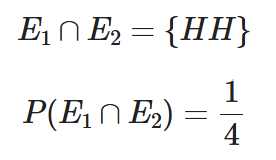

The product of the individual probabilities is

 
 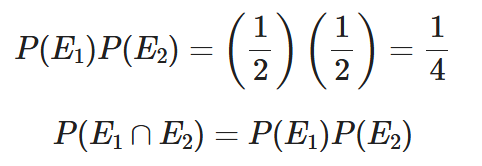


(E1) and (E2) are independent.

## Check independence of E1 and E3

The intersection is

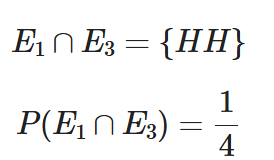

The product of the individual probabilities is

 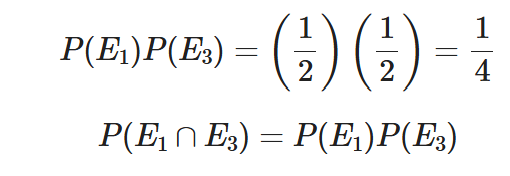
 
(E1) and (E3) are independent.

## Check independence of E2 and E3
The intersection is

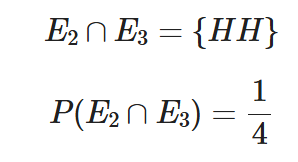

The product of the individual probabilities is
 
 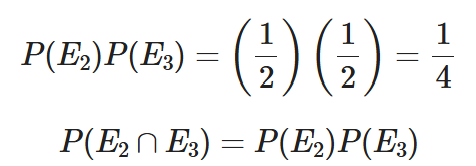

(E2) and (E3) are independent.

Therefore, all three pairs are independent, so the events are pairwise independent.

## Check Mutual Independence

For three events to be mutually independent, they must satisfy

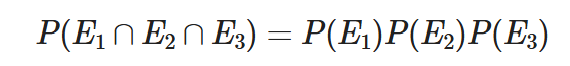

The triple intersection is

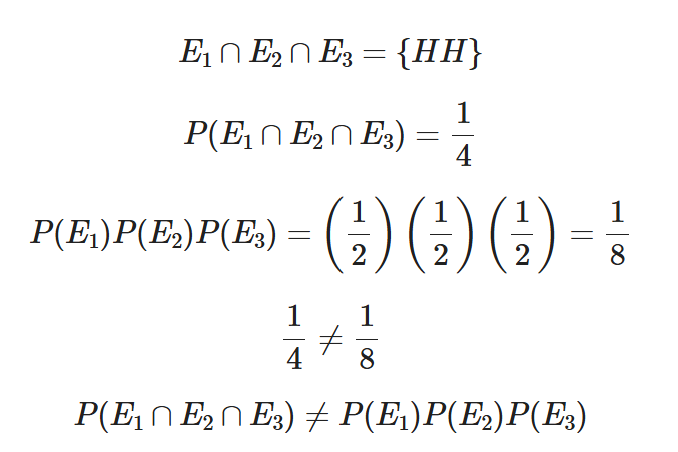

Therefore, the three events are not mutually independent.

## Conclusion

The events (E1), (E2), and (E3) are pairwise independent because every pair satisfies

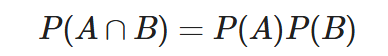

However, they are not mutually independent because

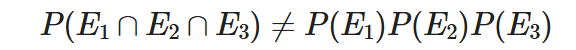

Therefore, pairwise independence does not imply mutual independence.

In [111]:
import numpy as np

seed = 5       
rng = np.random.default_rng(seed)

rng_step3 = rng.spawn(1)[0]
N = 10**6

# 1 = Heads, 0 = Tails
coin1 = rng_step3.integers(0, 2, size=N)
coin2 = rng_step3.integers(0, 2, size=N)

E1 = (coin1 == 1)          # First coin is heads
E2 = (coin2 == 1)          # Second coin is heads
E3 = (coin1 == coin2)      # Two coins match

P_E1 = np.mean(E1)
P_E2 = np.mean(E2)
P_E3 = np.mean(E3)

print("STEP 3 - PART 1")
print()

print("Individual probabilities:")
print("P(E1) =", P_E1)
print("P(E2) =", P_E2)
print("P(E3) =", P_E3)

STEP 3 - PART 1

Individual probabilities:
P(E1) = 0.500233
P(E2) = 0.499804
P(E3) = 0.500265


In [112]:
# Joint probabilities
P_E1E2 = np.mean(E1 & E2)
P_E1E3 = np.mean(E1 & E3)
P_E2E3 = np.mean(E2 & E3)
P_E1E2E3 = np.mean(E1 & E2 & E3)

# Products
prod_E1E2 = P_E1 * P_E2
prod_E1E3 = P_E1 * P_E3
prod_E2E3 = P_E2 * P_E3
prod_E1E2E3 = P_E1 * P_E2 * P_E3

print(f"{'Comparison':<20} {'Joint':<15} {'Product':<15} {'Difference':<15}")
print("_" * 65)

print(f"{'E1 and E2':<20} "
      f"{P_E1E2:<15.6f} "
      f"{prod_E1E2:<15.6f} "
      f"{abs(P_E1E2-prod_E1E2):<15.6f}")

print(f"{'E1 and E3':<20} "
      f"{P_E1E3:<15.6f} "
      f"{prod_E1E3:<15.6f} "
      f"{abs(P_E1E3-prod_E1E3):<15.6f}")

print(f"{'E2 and E3':<20} "
      f"{P_E2E3:<15.6f} "
      f"{prod_E2E3:<15.6f} "
      f"{abs(P_E2E3-prod_E2E3):<15.6f}")

print(f"{'E1,E2,E3':<20} "
      f"{P_E1E2E3:<15.6f} "
      f"{prod_E1E2E3:<15.6f} "
      f"{abs(P_E1E2E3-prod_E1E2E3):<15.6f}")

Comparison           Joint           Product         Difference     
_________________________________________________________________
E1 and E2            0.250151        0.250018        0.000133       
E1 and E3            0.250151        0.250249        0.000098       
E2 and E3            0.250151        0.250034        0.000117       
E1,E2,E3             0.250151        0.125075        0.125076       


In [113]:
N = 10**6

X = rng_step3.integers(0, 2, size=N)
error1 = rng_step3.random(N) < 0.1 # Receiver 1 error probability = 0.1
error2 = rng_step3.random(N) < 0.3 # Receiver 2 error probability = 0.3

# XOR flips the transmitted bit when an error occurs.
Y1 = X ^ error1.astype(int)
Y2 = X ^ error2.astype(int)

# Overall Pearson correlation
rho_all = np.corrcoef(Y1, Y2)[0, 1]

# Transmitted bit X = 0
mask0 = (X == 0)
Y1_X0 = Y1[mask0]
Y2_X0 = Y2[mask0]
rho_X0 = np.corrcoef(Y1_X0, Y2_X0)[0, 1]

# Transmitted bit X = 1
mask1 = (X == 1)
Y1_X1 = Y1[mask1]
Y2_X1 = Y2[mask1]
rho_X1 = np.corrcoef(Y1_X1, Y2_X1)[0, 1]

# Number of samples in each conditional subset
N_X0 = len(Y1_X0)
N_X1 = len(Y1_X1)

# Standard errors
def correlation_se(r, n):
    return (1 - r**2) / np.sqrt(n - 3)
se_all = correlation_se(rho_all, N)
se_X0 = correlation_se(rho_X0, N_X0)
se_X1 = correlation_se(rho_X1, N_X1)

print("STEP 3 - PART 2")
print()

print(f"{'Condition':<22} {'Samples':<12} {'Correlation':<15} {'Stdandard Error':<15}")
print("_" * 66)

print(f"{'All transmissions':<22} "
      f"{N:<12} "
      f"{rho_all:<15.6f} "
      f"{se_all:<15.6f}")

print(f"{'Given X = 0':<22} "
      f"{N_X0:<12} "
      f"{rho_X0:<15.6f} "
      f"{se_X0:<15.6f}")

print(f"{'Given X = 1':<22} "
      f"{N_X1:<12} "
      f"{rho_X1:<15.6f} "
      f"{se_X1:<15.6f}")

STEP 3 - PART 2

Condition              Samples      Correlation     Stdandard Error
__________________________________________________________________
All transmissions      1000000      0.320854        0.000897       
Given X = 0            499961       -0.000353       0.001414       
Given X = 1            500039       0.000623        0.001414       


If two sensor readings share a common cause but the fusion system assumes they are independent, the system may process the same underlying information multiple times and become overconfident in its estimate.

STEP 4

Bernouli trials and the binomial
Sample mean:      5.003350
Theoretical mean: 5.000000
Mean Difference:  0.003350

Sample Variance: 4.965208
Theoretical Variance: 4.975000
Variance: -0.009792


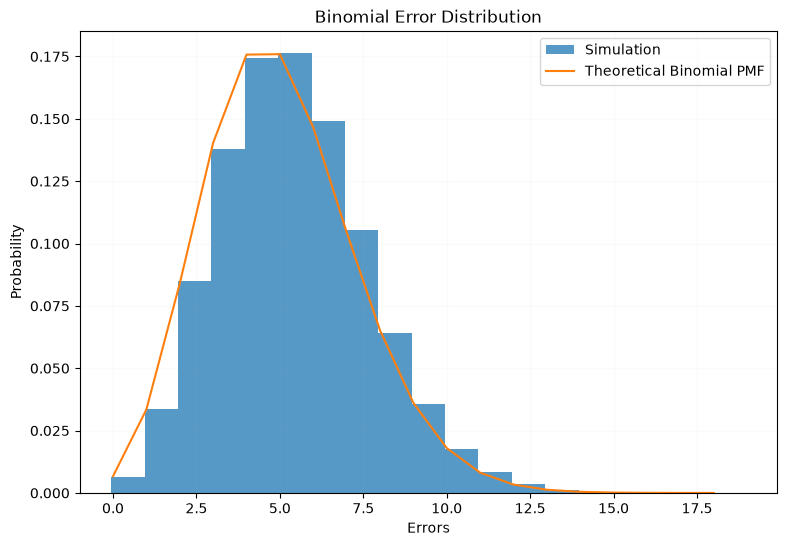


Clean Packet Probabilities
p = 0.005
Theoretical Probability: 0.006654
Emperical Probability:   0.006730
Difference:              0.000076
Error:                   0.000257

p = 0.001
Theoretical Probability: 0.367695
Emperical Probability:   0.369530
Difference:              0.001835
Error:                   0.001525

p = 0.0001
Theoretical Probability: 0.904833
Emperical Probability:   0.903790
Difference:              -0.001043
Error:                   0.000928



In [114]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy.stats import binom
from mp1lib import packet_errors 

# unique group seed 
SEED = 5 
rng = np.random.default_rng(SEED)
rng4 = rng.spawn(1)[0]

#pararmeters
N_pkt = 100000
N_bits = 1000
P_error = .005

errors = packet_errors( 
    n_pkt = N_pkt,
    n_bits = N_bits,
    p = P_error,
    rng  = rng4
)

#calculations 
sample_mean = np.mean(errors)
sample_var = np.var(errors, ddof =1)
theoretical_mean = N_bits * P_error
theoretical_var = N_bits * P_error * (1 - P_error) 
mean_diff = sample_mean - theoretical_mean
var_diff = sample_var - theoretical_var
mean_error = np.sqrt(theoretical_var / N_pkt)

print("Bernouli trials and the binomial") 
print(f"Sample mean:      {sample_mean:.6f}")
print(f"Theoretical mean: {theoretical_mean:.6f}")
print(f"Mean Difference:  {mean_diff:.6f}")
print()
print(f"Sample Variance: {sample_var:.6f}")
print(f"Theoretical Variance: {theoretical_var:.6f}")
print(f"Variance: {var_diff:.6f}")

#plot
plt.figure(figsize = (9,6)) 
plt.hist(
    errors,
    bins = np.arange(errors.max() +2) -.05,
    density = True,
    alpha = .75,
    label = "Simulation"
)

k_values = np.arange(0,errors.max()+1) 

binomial_pmf = binom.pmf(
    k_values,
    n = N_bits,
    p = P_error
)

plt.plot(
    k_values,
    binomial_pmf,
    markersize = 5,
    label = "Theoretical Binomial PMF"
)

plt.xlabel("Errors")
plt.ylabel("Probability")
plt.title("Binomial Error Distribution")
plt.legend()
plt.grid(alpha = .05)
plt.show()

print()
print("Clean Packet Probabilities")

p_val = [.005, .001, .0001]
for p in p_val: 
    packet_error_clean = packet_errors(
    n_pkt = N_pkt,
    n_bits = N_bits,
    p = p,
    rng = rng4
    )
    theoretical_clean = (1 - p) ** N_bits
    emperical_clean = np.mean(packet_error_clean == 0)
    difference = emperical_clean - theoretical_clean
    Error = np.sqrt( theoretical_clean * (1 -theoretical_clean) / N_pkt)
    
    print(f"p = {p}")
    print(f"Theoretical Probability: {theoretical_clean:.6f}")
    print(f"Emperical Probability:   {emperical_clean:.6f}")
    print(f"Difference:              {difference:.6f}")
    print(f"Error:                   {Error:.6f}")
    print()

STEP 5


In [83]:
#Test tv_distance on two identical pmfs
print("TV distance on two identical pmfs: ",tv_distance(np.array([0.2, 0.8]), np.array([0.2, 0.8])))

#Test tv_distance on two pmfs with disjoint support
print("TV distance on two pmfs with disjoint support: ",tv_distance(np.array([1.0, 0.0]), np.array([0.0, 1.0])))

TV distance on two identical pmfs:  0.0
TV distance on two pmfs with disjoint support:  1.0


In [104]:
import numpy as np
import pandas as pd
from scipy.stats import binom, poisson
#Computing exact Binomial pmf and Poisson pmf with same mean and their distance under 5 cases to print a table 
n = 1000
p_values = [0.5, 0.05, 0.005, 0.001, 0.0005]
results = []
for p in p_values:
#Equation for truncating the PMF
    #Poisson pmf mean
    lam = n * p
    K = int(np.ceil(lam + 20*np.sqrt(lam) + 20))
    k = np.arange(K + 1)
#Computing exact Binomial pmf and Poisson pmf with same mean
    binom_pmf = binom.pmf(k, n, p)
    poisson_pmf = poisson.pmf(k, lam)
#compute distance for the five cases
    distance = tv_distance(binom_pmf, poisson_pmf)
    """compute remaining poisson probability tail beyond K to print next to each ditance and show 
    that the truncation didn't matter"""
    poisson_tail = poisson.sf(K, lam)
#place the 5 cases in a list called results
    results.append((p, lam, K, distance, poisson_tail))
# Print a table for the data
distance_table = pd.DataFrame(results, columns=["p", "lambda = np", "K", "TV Distance", "Poisson Tail > K"])
print(distance_table.to_string(index=False))

     p  lambda = np   K  TV Distance  Poisson Tail > K
0.5000        500.0 968     0.166057      4.572865e-77
0.0500         50.0 212     0.012446      1.895351e-65
0.0050          5.0  70     0.001228      3.605448e-55
0.0010          1.0  41     0.000276      2.680655e-52
0.0005          0.5  35     0.000114      2.405163e-53


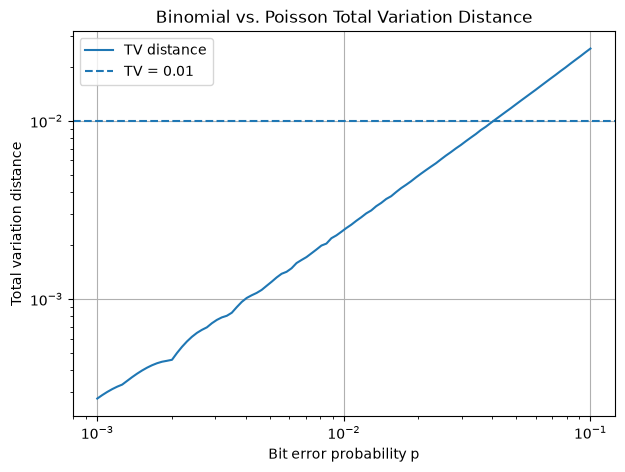

In [93]:
#plot distance on a grid and confirm it increases with p
p_grid = np.logspace(-3, -1, 100)
tv_grid = []
for p in p_grid:
    lam = n * p
    K = int(np.ceil(lam + 20*np.sqrt(lam) + 20))
    k = np.arange(K + 1)
    binom_pmf = binom.pmf(k, n, p)
    poisson_pmf = poisson.pmf(k, lam)
    distance = tv_distance(binom_pmf, poisson_pmf)
    tv_grid.append(distance)
#create the grid
plt.figure(figsize=(7, 5))
plt.loglog(p_grid, tv_grid, label="TV distance")
plt.axhline(0.01, linestyle="--", label="TV = 0.01")
plt.xlabel("Bit error probability p")
plt.ylabel("Total variation distance")
plt.title("Binomial vs. Poisson Total Variation Distance")
plt.legend()
plt.grid(True)
plt.show()

In [102]:
#Finding the value of p for which for which the distance stays below .01 using bisection 
def tv_for_p(p, n=1000):
    lam = n * p
    K = int(np.ceil(lam + 20*np.sqrt(lam) + 20))
    k = np.arange(K + 1)
    binom_pmf = binom.pmf(k, n, p)
    poisson_pmf = poisson.pmf(k, lam)
    return tv_distance(binom_pmf, poisson_pmf)
#setting the bracket of p from .001 to .1 to find the value of p for which the distance stays below .01
p_low = 0.001
p_high = 0.1
for _ in range(50):
    p_mid = (p_low + p_high) / 2
    d_mid = tv_for_p(p_mid)
    if d_mid < 0.01:
        p_low = p_mid
    else:
        p_high = p_mid
p_threshold = p_low
tv_threshold = tv_for_p(p_threshold)
#Print the value of the largest p with TV distance less than .01 to two sig figs
print("Largest p with TV distance < 0.01:")
print(f"p = {p_threshold:.3f}")
print(f"TV distance = {tv_threshold:.6f}")

Largest p with TV distance < 0.01:
p = 0.040
TV distance = 0.010000


In [98]:
#Obtaining distance using Le Cam bound to compare probabilities
p_lecam = np.sqrt(0.01 / n)
print(f"Le Cam p at bound = 0.01: {p_lecam:.4f}")

Le Cam p at bound = 0.01: 0.0032


Since .0404 is greater that .0032, the probability of the bisection answer is greater than the Le Cam bound because the Le Cam result is an upper bound, which states the distance is less than or equal to np^2, and that means that even though the bound is .01, the distance has a possibility to be smaller than that to make the statement true.

The Poisson approximation is trustworthy when n is large and p is small so that the mean or lambda remains reasonable.

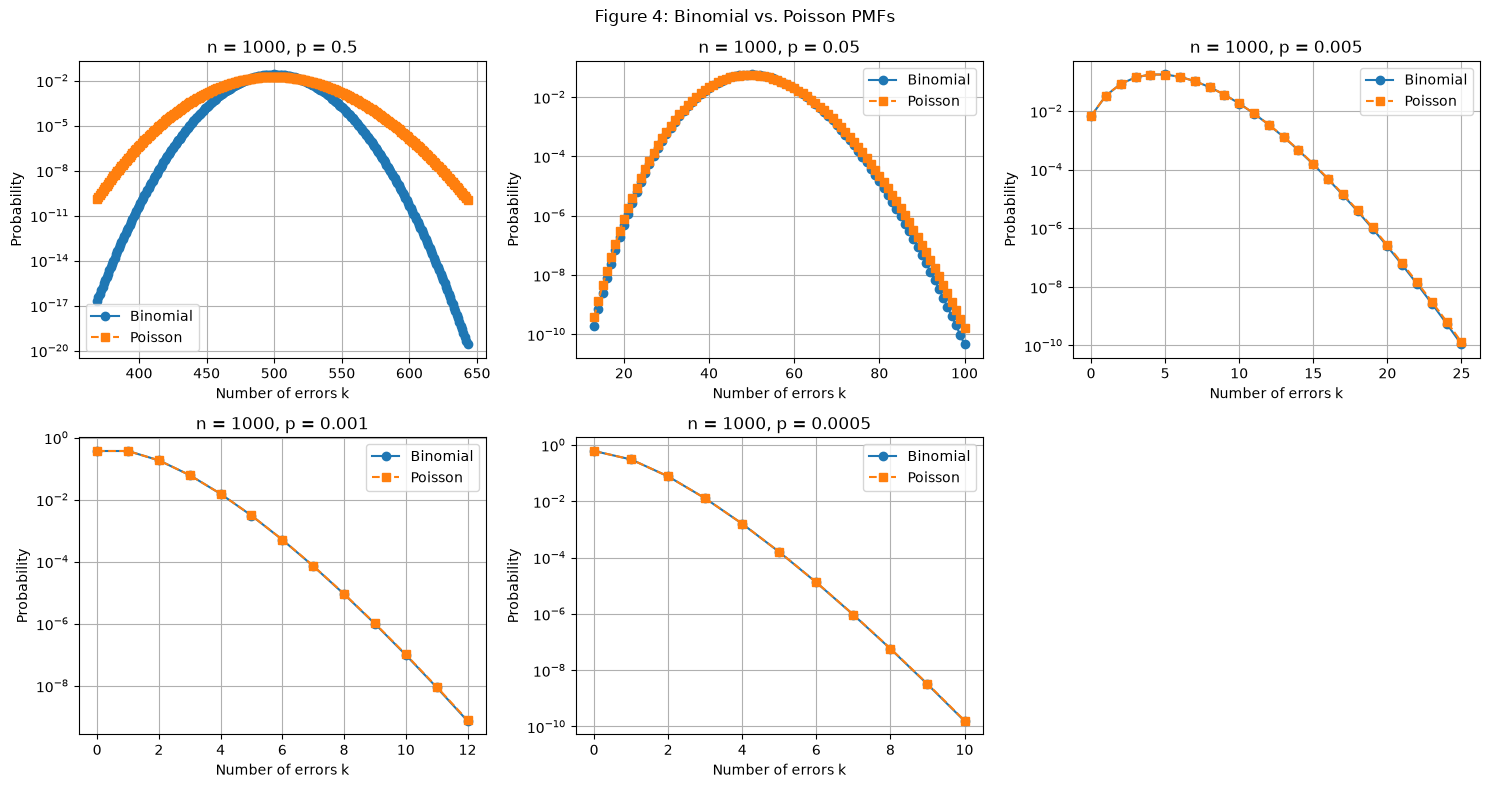

In [100]:
#Figure 4 using 2x3 grid
def get_common_support(n, p):
    lam = n * p
    K = int(np.ceil(lam + 20 * np.sqrt(lam) + 20))
    K = min(K, n)
    k = np.arange(K + 1)
    return lam, K, k
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for i, p in enumerate(p_values):
    #Calculate lambda and support
    lam, K, k = get_common_support(n, p)
    # Calculate the two PMFs
    binom_pmf = binom.pmf(k, n, p)
    poisson_pmf = poisson.pmf(k, lam)
    #Find the region where at least one PMF is not negligible
    significant = (binom_pmf > 1e-10) | (poisson_pmf > 1e-10)
    #Get x values in that region
    k_plot = k[significant]
    #Obtain corresponding probabilities
    binom_plot = binom_pmf[significant]
    poisson_plot = poisson_pmf[significant]
    #Plot Binomial
    axes[i].plot(k_plot, binom_plot, 'o-', label='Binomial')
    # Plot Poisson
    axes[i].plot(k_plot, poisson_plot, 's--', label='Poisson')
    #Set up grid
    axes[i].set_yscale('log')
    axes[i].set_xlabel('Number of errors k')
    axes[i].set_ylabel('Probability')
    axes[i].set_title(f'n = 1000, p = {p}')
    axes[i].legend()
    axes[i].grid(True)
#Turn off the unused sixth grid
axes[5].axis('off')
plt.suptitle('Figure 4: Binomial vs. Poisson PMFs')
plt.tight_layout()
plt.show()

This is figure 4 and it compares the different pmfs with different probabilities to show when Poisson approximation should be used. As we can see that for larger p values, the graphs are noticeably different, which means that Poisson aprroximation shouldn't be done. As p decreases and and the n trials remain at 1000, we notice that Poisson approximation gets closer to Binomial. Thus, when p is small, and n remains large, we can use Poisson approximation. 

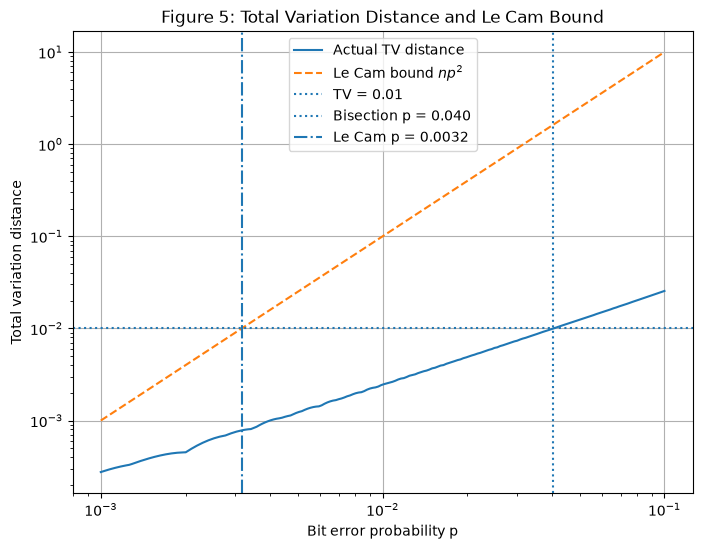

In [103]:
#Figure 5 total variation distance against p
p_grid = np.logspace(-3, -1, 200)
#Calculate actual TV distance
tv_values = np.array([tv_for_p(p, n) for p in p_grid])
#Calculate Le Cam bound
lecam_values = n * p_grid**2
#Calculate the two important p values
p_threshold = 0.0403935857
p_lecam = np.sqrt(0.01 / n)
#Create Figure 5
plt.figure(figsize=(8, 6))
plt.loglog(p_grid, tv_values, label='Actual TV distance')
plt.loglog(p_grid, lecam_values, '--', label=r'Le Cam bound $np^2$')
#TV as 0.01 reference line
plt.axhline(0.01, linestyle=':', label='TV = 0.01')
#Mark bisection result
plt.axvline(p_threshold, linestyle=':', label=f'Bisection p = {p_threshold:.3f}')
# Mark Le Cam point
plt.axvline(p_lecam, linestyle='-.', label=f'Le Cam p = {p_lecam:.4f}')
#Labels
plt.xlabel('Bit error probability p')
plt.ylabel('Total variation distance')
plt.title('Figure 5: Total Variation Distance and Le Cam Bound')
plt.legend()
plt.grid(True)
plt.show()

In the Figure 5, we notice that total variation distance increases when probability p increases, which means that when p is small Poisson approximation is accurate. Thus, the true tv distance at p=.01 is .040 and the only reason that Le Cam has a lower value is because it measures the upper bound at .01 and any other actual distance.

STEP 6

Because each attempt's success is independent from one another and there are only two possible outcomes (success or failure), we can see the number of attempts until the first clean packet meets the requirements to be geometric. Because the Geometric distribution describes probability of success compared to number of unsuccesful trials, it is a good fit for our application.

The function call we use in our library is rng.geometric, which uses the number of attempts rather than the number of failures, meaning it starts at 1 rather than 0.

This means it uses he number of attempts until the first clean packet meets the requirements to be geometric. Because the Geometric distribution describes probability of success compared to number of unsuccesful trials, it is a good fit for our application.

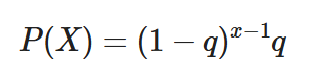

where q is the probability of success on each attempt and x is the number of attempts starting at 1.

The function call we use in our library is rng.geometric, which uses the number of attempts rather than the number of failures, meaning it starts at 1 rather than 0.

This means it uses

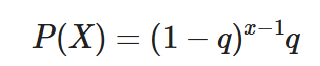

where q is the probability of success on each attempt and x is the number of attempts starting at 1.

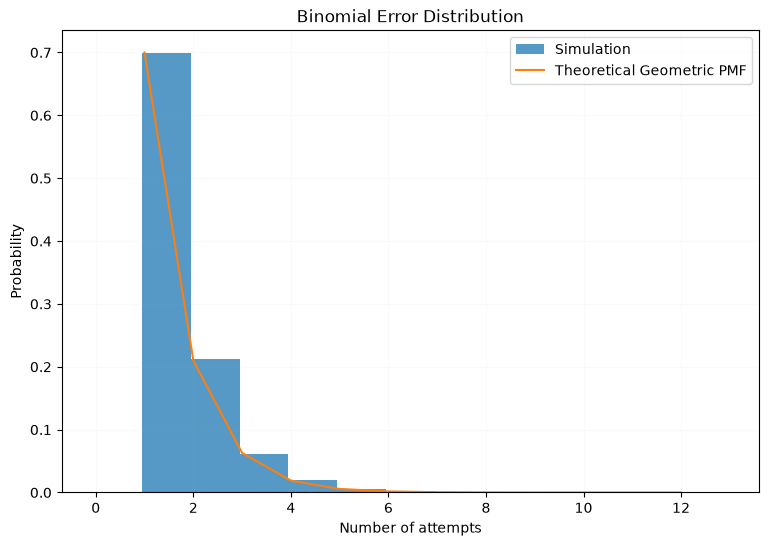

In [117]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy.stats import binom
from mp1lib import attempts_until_clean 

#parameters
q = 0.7
num_of_packets = 10**5

rng = np.random.default_rng(5)
rng4 = rng.spawn(1)[0]

#attempts until clean with the defined parameters
attempts = attempts_until_clean(num_of_packets, q, rng4)

#plot
plt.figure(figsize = (9,6)) 
plt.hist(
    attempts,
    bins = np.arange(attempts.max() +2) -.05,
    density = True,
    alpha = .75,
    label = "Simulation"
)
#Plot the theoretical curve


arr = np.arange(1,attempts.max()+1) 
geometric_pmf = geom.pmf(arr, q)

plt.plot(
    arr,
    geometric_pmf,
    markersize = 5,
    label = "Theoretical Geometric PMF"
)

plt.xlabel("Number of attempts")
plt.ylabel("Probability")
plt.title("Binomial Error Distribution")
plt.legend()
plt.grid(alpha = .05)
plt.show()

Sample Mean and Variance for all forms:

In [118]:
#calculations 
sample_mean = np.mean(attempts)
sample_var = np.var(attempts, ddof =1)
#theortical mean for attempts is 1/p
theoretical_mean_attempts = 1/q
theoretical_var_attempts = (1-q)/q**2
theoretical_mean_failures = (1-q)/q
theoretical_var_failures = (1-q)/q**2
#theoretical_var = num_of_packets * P_error * (1 - P_error) 
mean_diff = sample_mean - theoretical_mean_attempts
var_diff = sample_var - theoretical_var_attempts


print("Bernouli trials and the binomial") 
print(f"Sample mean:      {sample_mean:.6f}")
print(f"Theoretical mean, Attempts: {theoretical_mean_attempts:.6f}")
print(f"Theoretical mean, Failures: {theoretical_mean_failures:.6f}")
print(f"Difference of Mean:  {mean_diff:.6f}")
print()
print(f"Sample Variance: {sample_var:.6f}")
print(f"Theoretical Variance, Attempts: {theoretical_var_attempts:.6f}")
print(f"Theoretical Variance, Failures: {theoretical_var_failures:.6f}")
print(f"Difference of Variance: {var_diff:.6f}")

Bernouli trials and the binomial
Sample mean:      1.429360
Theoretical mean, Attempts: 1.428571
Theoretical mean, Failures: 0.428571
Difference of Mean:  0.000789

Sample Variance: 0.609896
Theoretical Variance, Attempts: 0.612245
Theoretical Variance, Failures: 0.612245
Difference of Variance: -0.002349


We will verify the memoryless property, which states the probability distribution is fully independent of its history. To do this, we find the probability that X is greater than a + b given that x is greater than a is just the probability of X being greater than b. This is written as:

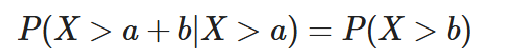

We can verify this using the pairs of a and b: (1,2), (3,2), and (5,2) First, for

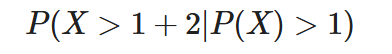

In [119]:
print(geometric_pmf[0])
print(geometric_pmf[1])

0.7
0.21000000000000002


Find conditional probability using:

 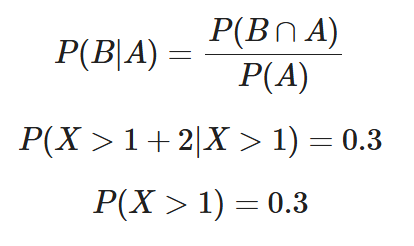

from 1-0.7 = 0.3

So, the PMF is memoryless for 1.

In [120]:
print(geometric_pmf[2]) #3
print(geometric_pmf[1]) #2

0.06300000000000001
0.21000000000000002


We now check (3,2)

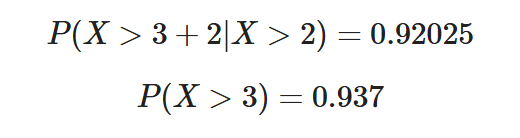

from 1- 0.063 = 0.937

In [121]:
print(geometric_pmf[4]) #3
print(geometric_pmf[1]) #2

0.005670000000000003
0.21000000000000002


We now check (5,2)

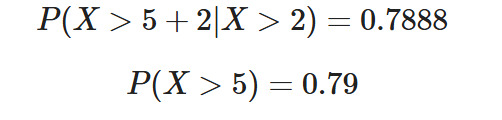

from 1- 0.063 = 0.937

A link that failed 5 times still is no more likely to succeed on the sixth attempt because the events are independent and do not depend on history. However, the assumption the probability is identical accross trials is not present in the real world; as a radio might have changing reception conditions over time.

STEP 7

In [122]:
import numpy as np
import matplotlib.pyplot as plt
SEED = 5
rng = np.random.default_rng(SEED)
rng_step7 = rng.spawn(1)[0]

# Parameter
N_bits = 1000
p_error = 0.005
q = 0.7
num_runs = 200
# 30 log-spaced checkpoints from 10 to 10^5
checkpoints = np.unique(np.logspace(1, 5, 30).astype(int))

# Binomial from step 4
binomial_mean_theory = N_bits * p_error
binomial_var_theory = N_bits * p_error * (1 - p_error)

# Geometric from step 6
geometric_mean_theory = 1 / q
geometric_var_theory = (1 - q) / (q**2)

print("Binomial Distribution")
print("Theoretical Mean =", round(binomial_mean_theory, 6))
print("Theoretical Variance =", round(binomial_var_theory, 6))
print()
print("Geometric Distribution")
print("Theoretical Mean =", round(geometric_mean_theory, 6))
print("Theoretical Variance =", round(geometric_var_theory, 6))
print()
print("Number of checkpoints =", len(checkpoints))
print("Checkpoints:")
print(checkpoints)

Binomial Distribution
Theoretical Mean = 5.0
Theoretical Variance = 4.975

Geometric Distribution
Theoretical Mean = 1.428571
Theoretical Variance = 0.612245

Number of checkpoints = 30
Checkpoints:
[    10     13     18     25     35     48     67     92    126    174
    239    329    452    621    853   1172   1610   2212   3039   4175
   5736   7880  10826  14873  20433  28072  38566  52983  72789 100000]


In [123]:
# Run 200 Independent Experiments
binomial_running_means = np.zeros((num_runs, len(checkpoints)))

geometric_running_means = np.zeros((num_runs, len(checkpoints)))
for run in range(num_runs):
    binomial_total = 0.0
    geometric_total = 0.0
    previous_N = 0
    for j, N in enumerate(checkpoints):     
        block_size = N - previous_N # Number of new samples required
        binomial_samples = rng_step7.binomial(
            n=N_bits,
            p=p_error,
            size=block_size
        )
        binomial_total += np.sum(binomial_samples)
        binomial_running_means[run, j] = (
            binomial_total / N
        )
        geometric_samples = rng_step7.geometric(
            p=q,
            size=block_size
        )
        geometric_total += np.sum(geometric_samples)
        geometric_running_means[run, j] = (
            geometric_total / N
        )
        previous_N = N

print("Stored Binomial array shape:", binomial_running_means.shape)
print("Stored Geometric array shape:", geometric_running_means.shape)

Stored Binomial array shape: (200, 30)
Stored Geometric array shape: (200, 30)


In [124]:
# Average running mean 
binomial_average = np.mean(binomial_running_means, axis=0)
geometric_average = np.mean(geometric_running_means, axis=0)

# Use one standard deviation
binomial_spread = np.std(binomial_running_means, axis=0, ddof=1)
geometric_spread = np.std(geometric_running_means, axis=0, ddof=1)

# Find the checkpoint closest to N = 1000
match_index = np.argmin(np.abs(checkpoints - 1000))
N_match = checkpoints[match_index]

# spread at N approximately equal to 1000
binomial_scale = (binomial_spread[match_index] * np.sqrt(N_match))
geometric_scale = (geometric_spread[match_index] * np.sqrt(N_match))

binomial_envelope = (binomial_scale / np.sqrt(checkpoints))
geometric_envelope = (geometric_scale / np.sqrt(checkpoints))

print("1/sqrt(N) envelope matched at N =", N_match)

1/sqrt(N) envelope matched at N = 853


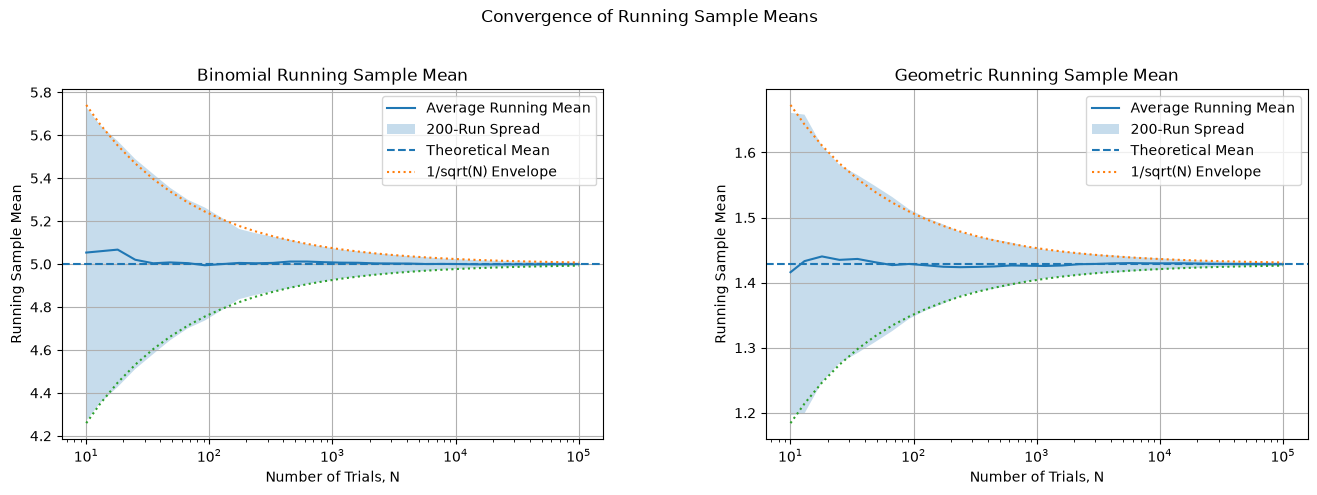

In [126]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1 - Binomial
ax[0].plot(checkpoints,
    binomial_average,
    label="Average Running Mean")
ax[0].fill_between(checkpoints,
    binomial_mean_theory - binomial_spread,
    binomial_mean_theory + binomial_spread,
    alpha=0.25, label="200-Run Spread")
ax[0].axhline(binomial_mean_theory, linestyle="--", label="Theoretical Mean")
ax[0].plot(checkpoints,
    binomial_mean_theory + binomial_envelope,
    linestyle=":", label="1/sqrt(N) Envelope")
ax[0].plot(checkpoints,
    binomial_mean_theory - binomial_envelope,
    linestyle=":")
ax[0].set_xscale("log")
ax[0].set_xlabel("Number of Trials, N")
ax[0].set_ylabel("Running Sample Mean")
ax[0].set_title("Binomial Running Sample Mean")
ax[0].grid(True)
ax[0].legend()

# Panel 2 - Geometric
ax[1].plot(checkpoints, geometric_average, label="Average Running Mean")
ax[1].fill_between(checkpoints,
    geometric_mean_theory - geometric_spread,
    geometric_mean_theory + geometric_spread,
    alpha=0.25, label="200-Run Spread")
ax[1].axhline(geometric_mean_theory, linestyle="--", label="Theoretical Mean")
ax[1].plot(checkpoints,
    geometric_mean_theory + geometric_envelope,
    linestyle=":", label="1/sqrt(N) Envelope")
ax[1].plot(checkpoints,
    geometric_mean_theory - geometric_envelope,
    linestyle=":")
ax[1].set_xscale("log")
ax[1].set_xlabel("Number of Trials, N")
ax[1].set_ylabel("Running Sample Mean")
ax[1].set_title("Geometric Running Sample Mean")
ax[1].grid(True)
ax[1].legend()

fig.suptitle("Convergence of Running Sample Means")
fig.subplots_adjust(
    left=0.08,
    right=0.97,
    bottom=0.12,
    top=0.82,
    wspace=0.30
)

plt.show()

The observed spread follows the 

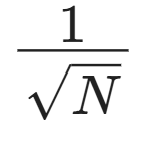
 
shape reasonably well. As N increases, the 200-run spread decreases at approximately the same rate as the scaled 

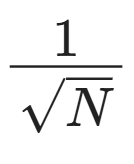
 
 envelope, with only small deviations due to finite simulation variability.

In [127]:
final_N = checkpoints[-1]

# Binomial comparison
binomial_final_estimate = binomial_average[-1]
binomial_difference = abs(binomial_final_estimate - binomial_mean_theory)
binomial_standard_error = (binomial_spread[-1]  / np.sqrt(num_runs))

# Geometric comparison
geometric_final_estimate = geometric_average[-1]
geometric_difference = abs(geometric_final_estimate - geometric_mean_theory)
geometric_standard_error = (geometric_spread[-1] / np.sqrt(num_runs))

print("THEORY VS SIMULATION COMPARISON")
print()

print("Binomial")
print("Theoretical Mean:", round(binomial_mean_theory, 6))
print("Simulation Mean:", round(binomial_final_estimate, 6))
print("Difference:", round(binomial_difference, 6))
print("Standard Error:", round(binomial_standard_error, 6))
print()

print("Geometric")
print("Theoretical Mean:", round(geometric_mean_theory, 6))
print("Simulation Mean:", round(geometric_final_estimate, 6))
print("Difference:", round(geometric_difference, 6))
print("Standard Error:", round(geometric_standard_error, 6))

THEORY VS SIMULATION COMPARISON

Binomial
Theoretical Mean: 5.0
Simulation Mean: 4.999835
Difference: 0.000165
Standard Error: 0.000443

Geometric
Theoretical Mean: 1.428571
Simulation Mean: 1.428332
Difference: 0.000239
Standard Error: 0.000168


In [128]:
# 1% CONVERGENCE
one_percent = 0.01 * binomial_mean_theory
C_values = (binomial_spread * np.sqrt(checkpoints))
C_est = np.median(C_values)

N_needed_est = (C_est / one_percent)**2

print("1% CONVERGENCE TEST")
print()
print("Theoretical Binomial Mean =", binomial_mean_theory)
print("1% of Theoretical Mean =", one_percent)
print("Estimated 1/sqrt(N) Constant =", round(C_est, 6))
print("Estimated Number of Trials =", round(N_needed_est))

1% CONVERGENCE TEST

Theoretical Binomial Mean = 5.0
1% of Theoretical Mean = 0.05
Estimated 1/sqrt(N) Constant = 2.324086
Estimated Number of Trials = 2161


Theoretical Check for the 1 Percent Requirement
For the Binomial distribution: 

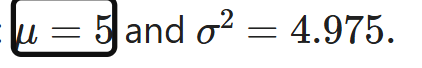

The standard deviation of the sample mean is

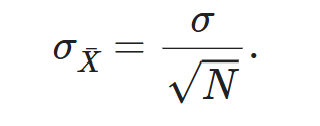
 

To make the spread smaller than 1 percent of the true mean,

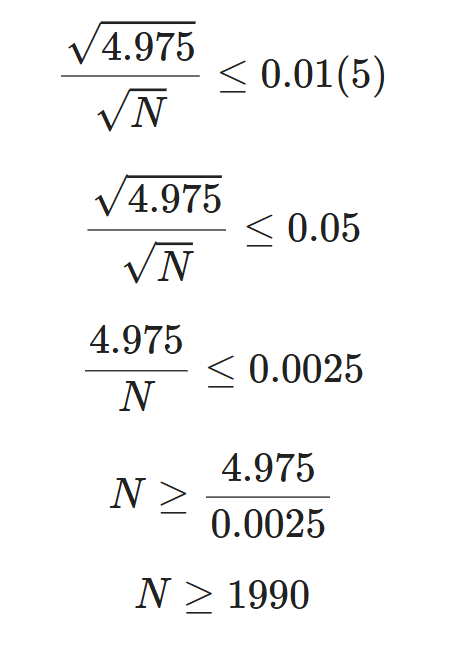

Using the observed 200-run spread, the fitted convergence behavior is approximately

 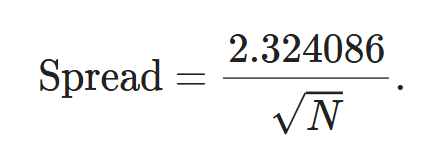

To determine when the spread reaches 1 percent of the true mean,

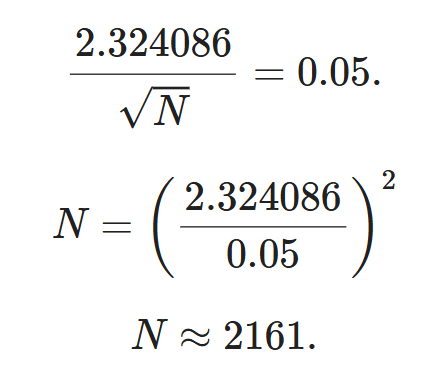

Therefore, based on the width of the 200-run empirical band, approximately

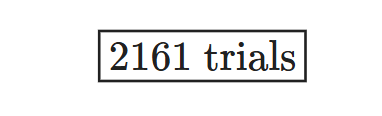

are needed for the Binomial sample mean to be within 1 percent of the true mean.

The theoretical prediction is approximately 1990 trials, so the empirical result is reasonably close to the theoretical expectation.

STEP 8

Probability that 1000 bit packet arrives clean occurs when all 1000 bits are recieved without an error. A packet is clean when X=0, thus, P(X=0) = (1000 choose 0)*p^0(1-p)^1000

(1000 choose 0) = 1

p^0 = 1

Since q=probability of success

q = (1-p)^1000


In [129]:
#The probability that the 1000 bit packet arrives clean 
packet_length = 1000
#Range of bit error probabilities
p_grid = np.logspace(-5, -2, 300)
#probability that all 1000 bits are correct
q_grid = (1 - p_grid)**packet_length
#Print the probability that the packet arrives clean
print("Clean packet probability:")
for p, q_value in zip([1e-5, 1e-4, 1e-3], (1 - np.array([1e-5, 1e-4, 1e-3]))**packet_length):
    print(f"p = {p:.1e}, q = {q_value:.6f}")

Clean packet probability:
p = 1.0e-05, q = 0.990050
p = 1.0e-04, q = 0.904833
p = 1.0e-03, q = 0.367695


Expected number of transmissions per deliver packet:

E(T)= 1/q

E(T)= 1/(1-p)^1000

E(T)= (1-p)^-1000

In [131]:
#expected number of transmissions per delivery packet
expected_transmissions = 1 / q_grid
print("Expected transmissions at selected p values:")
for p, q_value in zip([1e-5, 1e-4, 1e-3], (1 - np.array([1e-5, 1e-4, 1e-3]))**packet_length):
    expected = 1 / q_value
    print(f"p = {p:.1e}, E[T] = {expected:.6f}")

Expected transmissions at selected p values:
p = 1.0e-05, E[T] = 1.010050
p = 1.0e-04, E[T] = 1.105176
p = 1.0e-03, E[T] = 2.719642


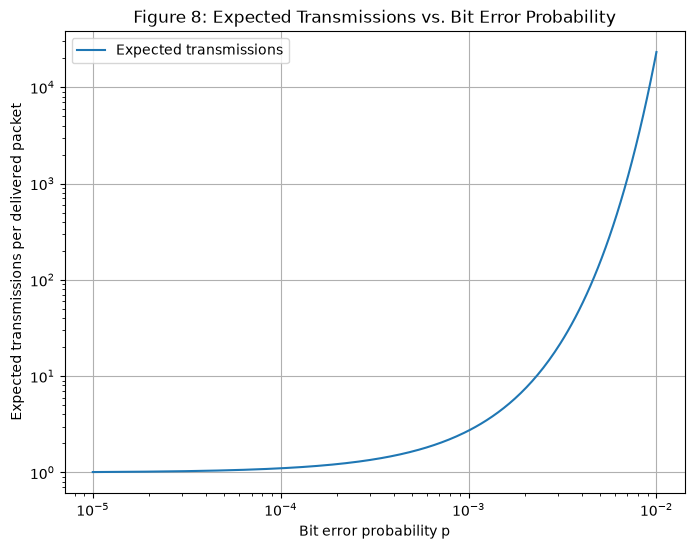

       p  Analytic E[T]  Simulated E[T]  Difference  Standard Error
0.000010       1.010050         1.01006    0.000010        0.000319
0.000032       1.032129         1.03206    0.000069        0.000580
0.000100       1.105176         1.10458    0.000596        0.001073
0.000316       1.372011         1.37142    0.000591        0.002269
0.001000       2.719642         2.72368    0.004038        0.006876


In [132]:
#Expected number of transmissions vs p plot
plt.figure(figsize=(8, 6))
plt.loglog(p_grid, expected_transmissions, label="Expected transmissions")
plt.xlabel("Bit error probability p")
plt.ylabel("Expected transmissions per delivered packet")
plt.title("Figure 8: Expected Transmissions vs. Bit Error Probability")
plt.grid(True)
plt.legend()
plt.show()

#Overlay simulated points, 5 values of p across 10^-5 to 10^-3 with error bars
N_sim = 100_000
#Five values spread across 10^-5 to 10^-3
p_sim = np.logspace(-5, -3, 5)
simulated_means = []
simulated_se = []
analytic_means = []
differences = []

for p in p_sim:
    #Analytical clean-packet probability
    q = (1 - p)**packet_length
    #Generate number of attempts until first clean packet
    attempts = attempts_until_clean(N_sim, q, rng_step8)
    #Simulated mean
    simulated_mean = np.mean(attempts)
    #Standard error of the simulated mean
    standard_error = np.std(attempts, ddof=1) / np.sqrt(N_sim)
    #Analytical mean
    analytic_mean = 1 / q
    #Absolute difference
    difference = abs(simulated_mean - analytic_mean)
    #Store results
    simulated_means.append(simulated_mean)
    simulated_se.append(standard_error)
    analytic_means.append(analytic_mean)
    differences.append(difference)

step8_table = pd.DataFrame({"p": p_sim, "Analytic E[T]": analytic_means, "Simulated E[T]": simulated_means,
"Difference": differences, "Standard Error": simulated_se})
print(step8_table.to_string(index=False))

The analytic curve remains valid out to 10^-2 because the clean packet probability is obtained from the Binomial model and the expected number of retransmissions follows the geometric distribution, which means that a bit by bit retransmission simulation isn't needed to evaluate the analytic curve and see that as p increases, so does the retransmissions.

E(T)= 2

E(T) = 1/(1-p)^1000

2 = 1/(1-p)^1000

1-p = 2^-1/1000

p = 1 - 2^-1/1000

In [133]:
#The value of p that requires more than 2 transmissions per delivery packet
p_two_transmissions = 1 - 2**(-1 / packet_length)
print(f"p where expected transmissions = 2: "f"{p_two_transmissions:.6e}")

p where expected transmissions = 2: 6.929070e-04


Gooput is the delivery bits/transmitted bits


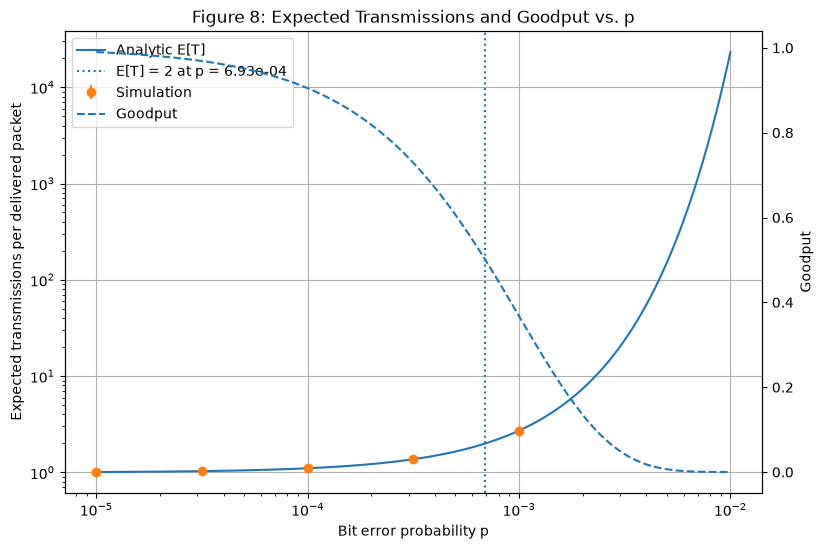

In [134]:
#Plot of goodput against p and the marked point for expected transmissions is more than 2 transmissions
goodput = q_grid
fig, ax1 = plt.subplots(figsize=(9, 6))
#Left axis: expected transmissions
ax1.loglog(p_grid, expected_transmissions, label="Analytic E[T]")
# Simulated points with error bars
ax1.errorbar(p_sim, simulated_means, yerr=simulated_se, fmt='o', label="Simulation")

#Mark E[T] = 2 point
ax1.axvline(p_two_transmissions, linestyle=':', label=f"E[T] = 2 at p = {p_two_transmissions:.2e}")
ax1.set_xlabel("Bit error probability p")
ax1.set_ylabel("Expected transmissions per delivered packet")
ax1.set_title("Figure 8: Expected Transmissions and Goodput vs. p")
ax1.grid(True)

#Right axis: goodput
ax2 = ax1.twinx()
ax2.semilogx(p_grid, goodput, linestyle='--', label="Goodput")
ax2.set_ylabel("Goodput")

#Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")
plt.show()

The figure 8 graph shows number of expected tranmsissions vs p to indicate that as p increases so does the number of expected transmissions per packet. It also indicates that when p is equal to or greater than 6.93e-4 then the number of expected transmissions is equal to or more than 2. The goodput plot also shows that as p increases, the number of delivery bits decrease per packet to show that the error is getting larger in the system. 

In [135]:
#Three packet lengths
packet_lengths = [100, 1000, 10000]
length_results = {}
for L in packet_lengths:
    q = (1 - p_grid)**L
    expected_T = 1 / q
    length_results[L] = {"q": q, "expected_T": expected_T}
#p where goodput is equal to 90%
p_90_results = []
for L in packet_lengths:
    p_90 = 1 - 0.90**(1 / L)
    p_90_results.append([L, p_90])
p_90_table = pd.DataFrame(p_90_results, columns=["Packet Length L", "p at Goodput = 0.90"])
print(p_90_table.to_string(index=False))

 Packet Length L  p at Goodput = 0.90
             100             0.001053
            1000             0.000105
           10000             0.000011


In [138]:
#simulation vs theory results for each packet length
for L in packet_lengths:
    print(f"\nPacket length L = {L}")
    print("-" * 60)
    for i, p_value in enumerate(p_sim):
        #Exact analytic value at this p
        q = (1 - p_value)**L
        analytic = 1 / q
        simulated = figure9_sim[L]["sim_mean"][i]
        difference = abs(simulated - analytic)
        se = figure9_sim[L]["sim_se"][i]
        print(f"p = {p_value:.3e}, "f"Analytic = {analytic:.6f}, "f"Simulation = {simulated:.6f}, "f"Difference = {difference:.6f}, "f"SE = {se:.6f}")


Packet length L = 100
------------------------------------------------------------
p = 1.000e-05, Analytic = 1.001001, Simulation = 1.000910, Difference = 0.000091, SE = 0.000095
p = 3.162e-05, Analytic = 1.003167, Simulation = 1.003180, Difference = 0.000013, SE = 0.000179
p = 1.000e-04, Analytic = 1.010051, Simulation = 1.009860, Difference = 0.000191, SE = 0.000315
p = 3.162e-04, Analytic = 1.032133, Simulation = 1.032040, Difference = 0.000093, SE = 0.000574
p = 1.000e-03, Analytic = 1.105226, Simulation = 1.105610, Difference = 0.000384, SE = 0.001081

Packet length L = 1000
------------------------------------------------------------
p = 1.000e-05, Analytic = 1.010050, Simulation = 1.009880, Difference = 0.000170, SE = 0.000317
p = 3.162e-05, Analytic = 1.032129, Simulation = 1.031610, Difference = 0.000519, SE = 0.000572
p = 1.000e-04, Analytic = 1.105176, Simulation = 1.104810, Difference = 0.000366, SE = 0.001076
p = 3.162e-04, Analytic = 1.372011, Simulation = 1.375840, Diff

In [139]:
#Print the probability at which the expected value of transmissions is 2 for each packet
print("E[T] = 2 transmission points:")
for L in packet_lengths:
    p_two = 1 - 2**(-1 / L)
    print(f"L = {L}: p = {p_two:.6e}")

E[T] = 2 transmission points:
L = 100: p = 6.907505e-03
L = 1000: p = 6.929070e-04
L = 10000: p = 6.931232e-05


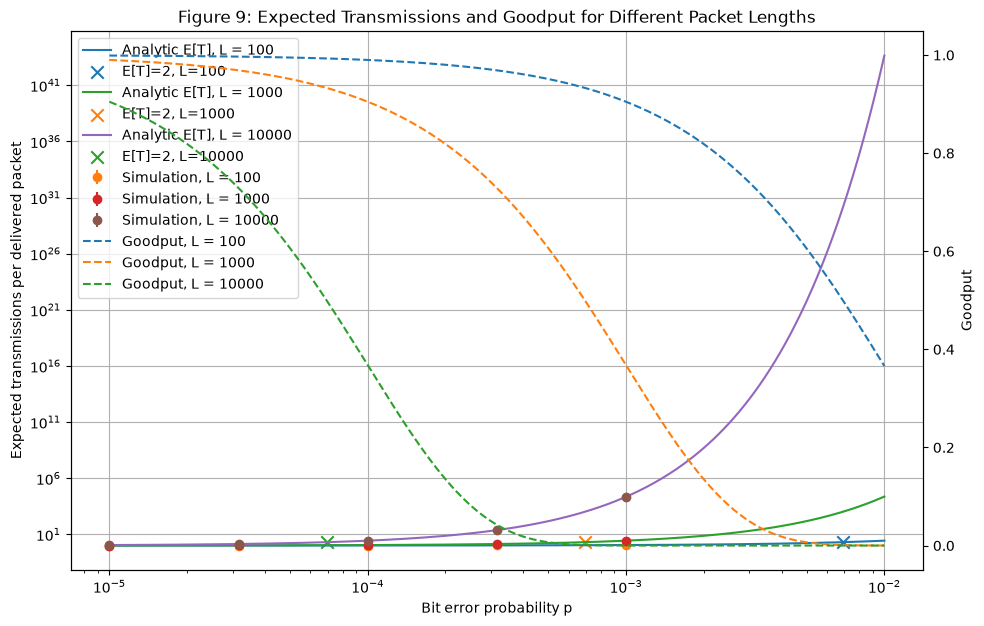

In [137]:
#Compare packet lengths L = 100, 1000, and 10000
packet_lengths = [100, 1000, 10000]
#Five simulation points required by the assignment
p_sim = np.logspace(-5, -3, 5)
#Number of simulated packets for each point
N_sim = 100_000
#Store simulation results
figure9_sim = {}
for L in packet_lengths:
    #Clean-packet probability
    q_curve = (1 - p_grid)**L
    #Expected number of transmissions
    expected_curve = 1 / q_curve
    sim_means = []
    sim_se = []
    for p_value in p_sim:
        #Clean probability for this packet length
        q = (1 - p_value)**L
        #Simulate attempts until first clean packet
        attempts = attempts_until_clean(N_sim, q, rng_step8)
        #Mean number of transmissions
        mean_attempts = np.mean(attempts)
        #Standard error of the mean
        se = np.std(attempts, ddof=1) / np.sqrt(N_sim)
        sim_means.append(mean_attempts)
        sim_se.append(se)
    #Store simulation results for this packet length
    figure9_sim[L] = {"q": q_curve, "expected": expected_curve, "sim_mean": np.array(sim_means), "sim_se": np.array(sim_se)}
#Graph figure 9 to compare the goodput values
fig, ax1 = plt.subplots(figsize=(11, 7))
for L in packet_lengths:
    #Get analytic and simulation data
    expected_curve = figure9_sim[L]["expected"]
    sim_mean = figure9_sim[L]["sim_mean"]
    sim_se = figure9_sim[L]["sim_se"]
    #Plot analytic expected transmissions
    ax1.loglog(p_grid, expected_curve, label=f"Analytic E[T], L = {L}")
    #Plot 5 simulation points with error bars
    ax1.errorbar(p_sim, sim_mean, yerr=sim_se, fmt='o', label=f"Simulation, L = {L}")
    #Calculate the E[T] = 2 location
    p_two = 1 - 2**(-1 / L)
    #Mark the point
    ax1.scatter(p_two, 2, marker='x', s=80, label=f"E[T]=2, L={L}")
#Labels
ax1.set_xlabel("Bit error probability p")
ax1.set_ylabel("Expected transmissions per delivered packet")
ax1.set_title("Figure 9: Expected Transmissions and Goodput for Different Packet Lengths")
ax1.grid(True)
#Goodput on second y-axis
ax2 = ax1.twinx()
for L in packet_lengths:
    q_curve = figure9_sim[L]["q"]
    ax2.semilogx(p_grid, q_curve, linestyle='--', label=f"Goodput, L = {L}")
ax2.set_ylabel("Goodput")
#Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")
plt.show()

This graph shows that increasing the packet length makes the link more sensitive to bit errors because every bit has an additional probability for corruption. Thus, the packets with less bits can handle larger bit error probability until the goodput drops below 90%. Therefore, as bit error probability increases and number of bits per packet increases, so does the expected number of transmissions, which means more transmissions are needed if the probability of error in a packet is higher. 

The bit error that this link needs to hold up to keep a goodput value of above 90% is different depending on the packet length. For instance, for a packet length of 100 the value is 0.001053, for a packet length of 1000 the value is 0.0001053, and for a packet length of 10000 the value is 0.00001053. Thus, as the packet length decreases from 1000 the probability of getting an error can increase without affecting the goodput value alot. Therefore, as the packet length increases, the probability of getting an error in a packet also increases because more bits are present with more error. In conclusion, although sending more per packet is efficient in a system, it can raise problems when each has a probability of getting an error.